<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/Actividad_21_10_26_OlistDataSets_Mauricio_Crescente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plantilla modelo en base a actividad de Procesamiento y Ciencia de Datos – Olist (E-Commerce Brasil)
**Alumno:** Crescente Mauricio
**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (~100.000 órdenes, 2016–2018, 9 tablas relacionales)

## Cómo está organizada esta plantilla
| Bloque | Contenido |
|---|---|
| **A** | Instalación, importación de librerías y descarga del dataset con `kagglehub` |
| **B** | Carga y vista de **cada una de las 9 tablas** (originales `raw_*`) |
| **C** | **Copias de trabajo** de cada tabla (los `raw_*` nunca se modifican) |
| **D** | **Joins** para unificar el grafo relacional en un único DataFrame maestro |
| **E** | Los **7 pasos** del pipeline + checklist final (esqueleto listo para completar con las consignas) |

**Regla de oro:** los DataFrames `raw_*` son los originales y no se tocan. Todo el trabajo se hace sobre las copias (`orders`, `customers`, ...) y luego sobre `df_master` / `df_work`.

**Organización del Colab:**

**Bloque A:** instalación de kagglehub e imbalanced-learn, imports y tu celda de descarga con dataset_download.

**Bloque B:** una celda por cada una de las 9 tablas (raw_*), con forma, head, info, nulos, duplicados y describe.

**Bloque C:** copias de trabajo (orders, customers, items, etc.) y una verificación de que no son el mismo objeto que los originales.

**Bloque D:** los joins ya armados:
* Primero se agregan los ítems, los pagos y la geolocalización a nivel de
orden.
* De las reseñas se conserva la más reciente por orden.
* Después se une todo a partir de orders con how='left'.
* Un control confirma que order_id siga siendo único y que las filas no se dupliquen.
* Al final se crea df_work como copia del maestro, con las fechas ya convertidas.

**Bloque E:** esqueleto de los 7 pasos y el checklist, tomados de tu modelo de churn. Los parámetros del caso (target, columnas, fecha de corte, variables de fuga) están juntos en una celda de configuración para completarlos con cada consigna.

## Modelo relacional de la base de datos (según diagrama)
| Tabla | Clave(s) | Se vincula con |
|---|---|---|
| `orders` | `order_id` (PK), `customer_id` (FK) | `customers`, `order_items`, `order_payments`, `order_reviews` |
| `customers` | `customer_id` (PK), `customer_zip_code_prefix` | `orders`, `geolocation` |
| `order_items` | `order_id` + `order_item_id`, `product_id`, `seller_id` | `orders`, `products`, `sellers` |
| `order_payments` | `order_id` + `payment_sequential` | `orders` |
| `order_reviews` | `review_id`, `order_id` | `orders` |
| `products` | `product_id` (PK) | `order_items`, `category_translation` |
| `sellers` | `seller_id` (PK), `seller_zip_code_prefix` | `order_items`, `geolocation` |
| `geolocation` | `geolocation_zip_code_prefix` (NO es único) | `customers`, `sellers` |
| `category_translation` | `product_category_name` | `products` |


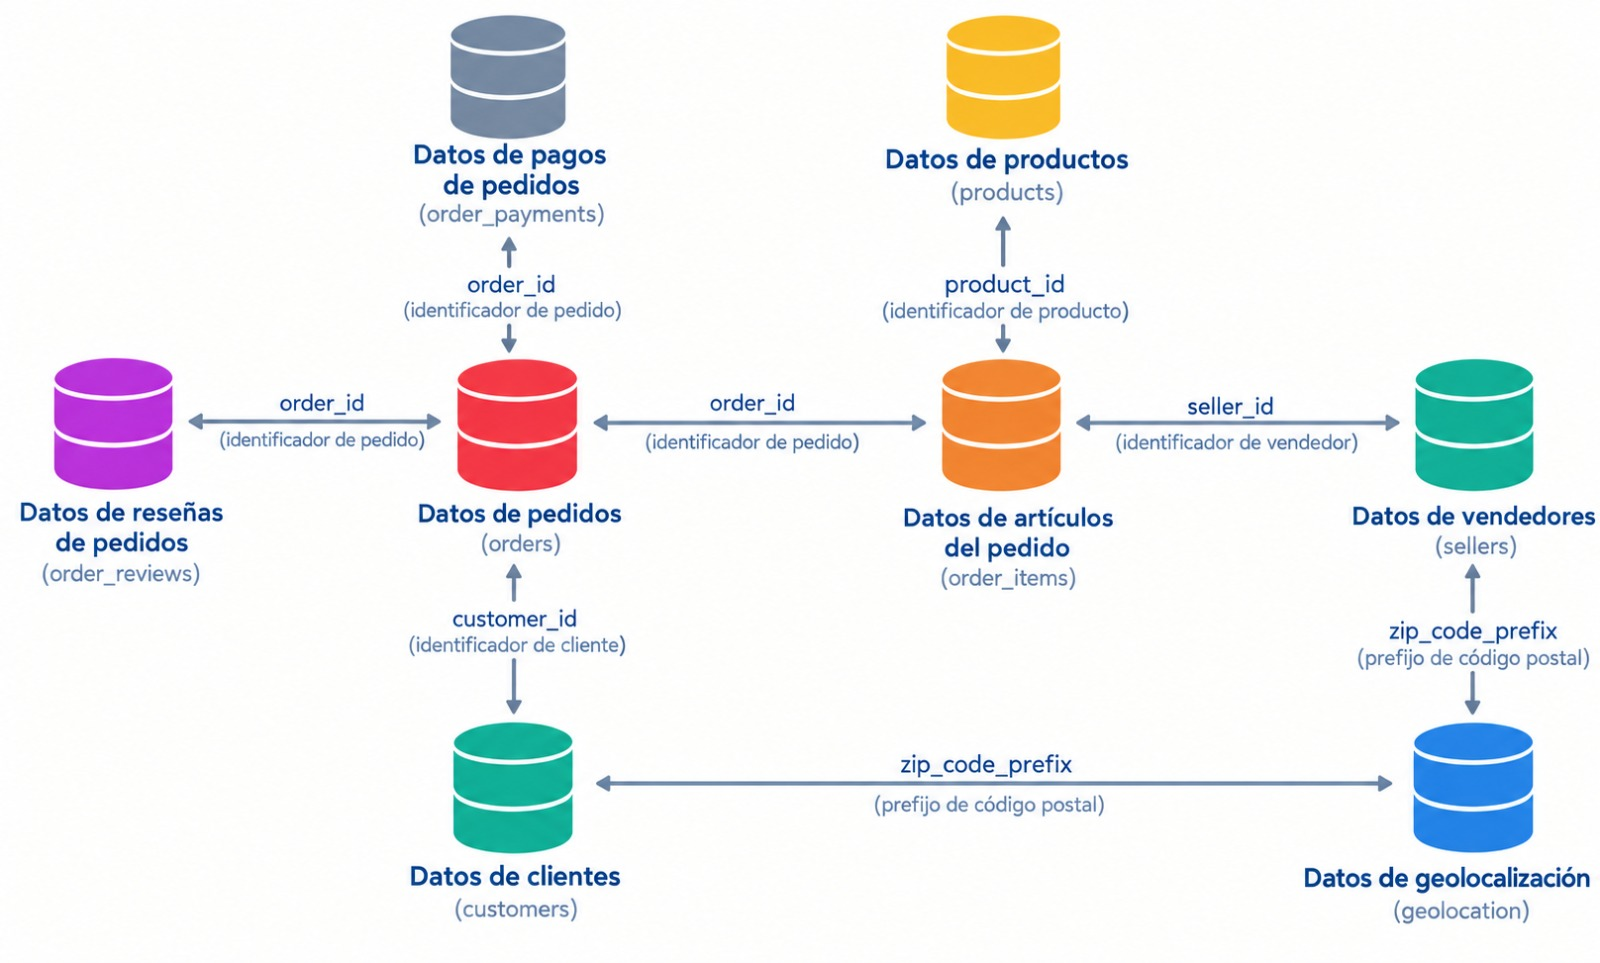

# BLOQUE A – Configuración e importación
## A.1 Instalación de librerías
`kagglehub` descarga el dataset desde Kaggle e `imbalanced-learn` aporta SMOTE (se usa en el Paso 7).

In [ ]:
# Instala kagglehub (descarga de datasets) e imbalanced-learn (SMOTE); -q silencia la salida
!pip install -q kagglehub imbalanced-learn

## A.2 Importación de librerías

In [ ]:
import os                                   # manejo de rutas y archivos del sistema
import warnings                             # control de avisos de Python
import numpy as np                          # cálculo numérico y arrays
import pandas as pd                         # manipulación de DataFrames
import matplotlib.pyplot as plt             # gráficos base
import seaborn as sns                       # gráficos estadísticos
from scipy import stats                     # tests estadísticos (chi-cuadrado, z-score)

warnings.filterwarnings('ignore')           # oculta advertencias para mantener limpia la salida
pd.set_option('display.max_columns', 60)    # muestra hasta 60 columnas al imprimir un DataFrame
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')  # formatea los decimales a 3 cifras
sns.set_theme(style='whitegrid')            # estilo visual por defecto de seaborn

## A.3 Descarga del dataset desde Kaggle

In [ ]:
import kagglehub                            # importa la librería de descarga

# Descarga la última versión del dataset y guarda en `path` la carpeta local donde quedó
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)       # muestra la ruta de la carpeta descargada

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [ ]:
# Lista los archivos CSV disponibles en la carpeta descargada
for archivo in sorted(os.listdir(path)):    # recorre los nombres de archivo en orden alfabético
    print(archivo)                          # imprime cada nombre (deben ser 9 CSV)

olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


# BLOQUE B – Carga y vista de cada tabla (originales `raw_*`)
Para cada tabla se hace lo mismo: leer el CSV, ver dimensiones, primeras filas, tipos de dato (`info`), nulos y estadísticos descriptivos.

## B.1 Tabla `orders`
Estado del pedido y marcas de tiempo del ciclo de vida (compra, aprobación, entrega, fecha estimada).

In [ ]:
# Lee el CSV de la tabla orders y lo guarda como original intocable (raw_orders)
raw_orders = pd.read_csv(os.path.join(path, 'olist_orders_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_orders.shape)  # cantidad de filas y columnas
display(raw_orders.head())                           # primeras 5 filas para ver el contenido

raw_orders.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_orders.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_orders.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_orders.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Columnas con nulos:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
Filas duplicadas exactas: 0


,count,unique,top,freq
order_id,99441,99441,66dea50a8b16d9b4dee7af250b4be1a5,1
customer_id,99441,99441,edb027a75a1449115f6b43211ae02a24,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-08-02 12:06:07,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-14 20:02:44,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


## B.2 Tabla `customers`
Datos del cliente: `customer_id` (por orden), `customer_unique_id` (persona real), ciudad, estado y prefijo postal.

In [ ]:
# Lee el CSV de la tabla customers y lo guarda como original intocable (raw_customers)
raw_customers = pd.read_csv(os.path.join(path, 'olist_customers_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_customers.shape)  # cantidad de filas y columnas
display(raw_customers.head())                           # primeras 5 filas para ver el contenido

raw_customers.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_customers.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_customers.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_customers.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,99441,99441,274fa6071e5e17fe303b9748641082c8,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_unique_id,99441,96096,8d50f5eadf50201ccdcedfb9e2ac8455,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_zip_code_prefix,"99,441.000",NaN,NaN,NaN,"35,137.475","29,797.939","1,003.000","11,347.000","24,416.000","58,900.000","99,990.000"
customer_city,99441,4119,sao paulo,15540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,99441,27,SP,41746,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## B.3 Tabla `order_items`
Detalle de productos por orden: producto, vendedor, precio y valor del flete. Una orden puede tener varios ítems.

In [ ]:
# Lee el CSV de la tabla order_items y lo guarda como original intocable (raw_items)
raw_items = pd.read_csv(os.path.join(path, 'olist_order_items_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_items.shape)  # cantidad de filas y columnas
display(raw_items.head())                           # primeras 5 filas para ver el contenido

raw_items.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_items.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_items.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_items.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.900,13.290
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.900,19.930
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.000,17.870
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.990,12.790
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.900,18.140


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,112650,98666,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_item_id,"112,650.000",NaN,NaN,NaN,1.198,0.705,1.000,1.000,1.000,1.000,21.000
product_id,112650,32951,aca2eb7d00ea1a7b8ebd4e68314663af,527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_id,112650,3095,6560211a19b47992c3666cc44a7e94c0,2033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_limit_date,112650,93318,2017-07-21 18:25:23,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,"112,650.000",NaN,NaN,NaN,120.654,183.634,0.850,39.900,74.990,134.900,"6,735.000"
freight_value,"112,650.000",NaN,NaN,NaN,19.990,15.806,0.000,13.080,16.260,21.150,409.680


## B.4 Tabla `order_payments`
Pagos por orden: tipo, cuotas y monto. Una orden puede tener varios métodos de pago.

In [ ]:
# Lee el CSV de la tabla order_payments y lo guarda como original intocable (raw_payments)
raw_payments = pd.read_csv(os.path.join(path, 'olist_order_payments_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_payments.shape)  # cantidad de filas y columnas
display(raw_payments.head())                           # primeras 5 filas para ver el contenido

raw_payments.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_payments.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_payments.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_payments.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.330
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.390
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.710
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.780
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.450


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,103886,99440,fa65dad1b0e818e3ccc5cb0e39231352,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_sequential,"103,886.000",NaN,NaN,NaN,1.093,0.707,1.000,1.000,1.000,1.000,29.000
payment_type,103886,5,credit_card,76795,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_installments,"103,886.000",NaN,NaN,NaN,2.853,2.687,0.000,1.000,1.000,4.000,24.000
payment_value,"103,886.000",NaN,NaN,NaN,154.100,217.494,0.000,56.790,100.000,171.838,"13,664.080"


## B.5 Tabla `order_reviews`
Reseñas: puntaje 1–5, título, comentario (en portugués) y fechas. Puede haber más de una reseña por orden.

In [ ]:
# Lee el CSV de la tabla order_reviews y lo guarda como original intocable (raw_reviews)
raw_reviews = pd.read_csv(os.path.join(path, 'olist_order_reviews_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_reviews.shape)  # cantidad de filas y columnas
display(raw_reviews.head())                           # primeras 5 filas para ver el contenido

raw_reviews.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_reviews.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_reviews.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_reviews.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB

Columnas con nulos:
review_comment_title      87656
review_comment_message    58247
dtype: int64
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,99224,98410,4548534449b1f572e357211b90724f1b,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,99224,98673,03c939fd7fd3b38f8485a0f95798f1f6,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_score,"99,224.000",NaN,NaN,NaN,4.086,1.348,1.000,4.000,5.000,5.000,5.000
review_comment_title,11568,4527,Recomendo,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_comment_message,40977,36159,Muito bom,230,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_creation_date,99224,636,2017-12-19 00:00:00,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_answer_timestamp,99224,98248,2017-06-15 23:21:05,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## B.6 Tabla `products`
Atributos del producto: categoría, peso y dimensiones (cm / g).

In [ ]:
# Lee el CSV de la tabla products y lo guarda como original intocable (raw_products)
raw_products = pd.read_csv(os.path.join(path, 'olist_products_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_products.shape)  # cantidad de filas y columnas
display(raw_products.head())                           # primeras 5 filas para ver el contenido

raw_products.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_products.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_products.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_products.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (32951, 9)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.000,287.000,1.000,225.000,16.000,10.000,14.000
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.000,276.000,1.000,"1,000.000",30.000,18.000,20.000
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.000,250.000,1.000,154.000,18.000,9.000,15.000
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.000,261.000,1.000,371.000,26.000,4.000,26.000
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.000,402.000,4.000,625.000,20.000,17.000,13.000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB

Columnas con nulos:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm     

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,32951,32951,106392145fca363410d287a815be6de4,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,32341,73,cama_mesa_banho,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name_lenght,"32,341.000",NaN,NaN,NaN,48.477,10.246,5.000,42.000,51.000,57.000,76.000
product_description_lenght,"32,341.000",NaN,NaN,NaN,771.495,635.115,4.000,339.000,595.000,972.000,"3,992.000"
product_photos_qty,"32,341.000",NaN,NaN,NaN,2.189,1.737,1.000,1.000,1.000,3.000,20.000
product_weight_g,"32,949.000",NaN,NaN,NaN,"2,276.472","4,282.039",0.000,300.000,700.000,"1,900.000","40,425.000"
product_length_cm,"32,949.000",NaN,NaN,NaN,30.815,16.914,7.000,18.000,25.000,38.000,105.000
product_height_cm,"32,949.000",NaN,NaN,NaN,16.938,13.638,2.000,8.000,13.000,21.000,105.000
product_width_cm,"32,949.000",NaN,NaN,NaN,23.197,12.079,6.000,15.000,20.000,30.000,118.000


## B.7 Tabla `sellers`
Datos del vendedor: prefijo postal, ciudad y estado.

In [ ]:
# Lee el CSV de la tabla sellers y lo guarda como original intocable (raw_sellers)
raw_sellers = pd.read_csv(os.path.join(path, 'olist_sellers_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_sellers.shape)  # cantidad de filas y columnas
display(raw_sellers.head())                           # primeras 5 filas para ver el contenido

raw_sellers.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_sellers.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_sellers.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_sellers.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (3095, 4)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
seller_id,3095,3095,9e25199f6ef7e7c347120ff175652c3b,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_zip_code_prefix,"3,095.000",NaN,NaN,NaN,"32,291.059","32,713.454","1,001.000","7,093.500","14,940.000","64,552.500","99,730.000"
seller_city,3095,611,sao paulo,694,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_state,3095,23,SP,1849,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## B.8 Tabla `geolocation`
Coordenadas (lat/lng) por prefijo postal. **El prefijo se repite muchas veces** (hay que agregarlo antes del join).

In [ ]:
# Lee el CSV de la tabla geolocation y lo guarda como original intocable (raw_geolocation)
raw_geolocation = pd.read_csv(os.path.join(path, 'olist_geolocation_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_geolocation.shape)  # cantidad de filas y columnas
display(raw_geolocation.head())                           # primeras 5 filas para ver el contenido

raw_geolocation.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_geolocation.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_geolocation.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_geolocation.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (1000163, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.546,-46.639,sao paulo,SP
1,1046,-23.546,-46.645,sao paulo,SP
2,1046,-23.546,-46.643,sao paulo,SP
3,1041,-23.544,-46.639,sao paulo,SP
4,1035,-23.542,-46.642,sao paulo,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 261831


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,"1,000,163.000",NaN,NaN,NaN,"36,574.166","30,549.336","1,001.000","11,075.000","26,530.000","63,504.000","99,990.000"
geolocation_lat,"1,000,163.000",NaN,NaN,NaN,-21.176,5.716,-36.605,-23.604,-22.919,-19.980,45.066
geolocation_lng,"1,000,163.000",NaN,NaN,NaN,-46.391,4.270,-101.467,-48.573,-46.638,-43.768,121.105
geolocation_city,1000163,8011,sao paulo,135800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geolocation_state,1000163,27,SP,404268,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## B.9 Tabla `category_translation`
Traducción de categorías de producto del portugués al inglés.

In [ ]:
# Lee el CSV de la tabla category_translation y lo guarda como original intocable (raw_translation)
raw_translation = pd.read_csv(os.path.join(path, 'product_category_name_translation.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_translation.shape)  # cantidad de filas y columnas
display(raw_translation.head())                           # primeras 5 filas para ver el contenido

raw_translation.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_translation.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_translation.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_translation.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (71, 2)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq
product_category_name,71,71,beleza_saude,1
product_category_name_english,71,71,health_beauty,1


# BLOQUE C – Copias de trabajo
`.copy()` crea una copia independiente: cualquier cambio sobre `orders`, `customers`, etc. **no** afecta a los `raw_*`.

In [ ]:
orders = raw_orders.copy()                  # copia de trabajo de órdenes
customers = raw_customers.copy()            # copia de trabajo de clientes
items = raw_items.copy()                    # copia de trabajo de ítems por orden
payments = raw_payments.copy()              # copia de trabajo de pagos
reviews = raw_reviews.copy()                # copia de trabajo de reseñas
products = raw_products.copy()              # copia de trabajo de productos
sellers = raw_sellers.copy()                # copia de trabajo de vendedores
geolocation = raw_geolocation.copy()        # copia de trabajo de geolocalización
translation = raw_translation.copy()        # copia de trabajo de traducción de categorías

# Verificación: son objetos distintos en memoria (modificar uno no altera el otro)
print('orders es el mismo objeto que raw_orders?:', orders is raw_orders)  # debe imprimir False

orders es el mismo objeto que raw_orders?: False


In [ ]:
# Resumen de control: filas y columnas de cada copia de trabajo
resumen = pd.DataFrame({
    'tabla': ['orders', 'customers', 'items', 'payments', 'reviews', 'products', 'sellers', 'geolocation', 'translation'],
    'filas': [len(d) for d in [orders, customers, items, payments, reviews, products, sellers, geolocation, translation]],
    'columnas': [d.shape[1] for d in [orders, customers, items, payments, reviews, products, sellers, geolocation, translation]],
})
display(resumen)                            # tabla resumen de tamaños

,tabla,filas,columnas
0,orders,99441,8
1,customers,99441,5
2,items,112650,7
3,payments,103886,5
4,reviews,99224,7
5,products,32951,9
6,sellers,3095,4
7,geolocation,1000163,5
8,translation,71,2


# BLOQUE D – Joins para vincular los DataFrames
**Idea central:** la unidad de análisis es la **orden** (`order_id`). Como `items`, `payments` y `reviews` tienen varias filas por orden, primero se **agregan a nivel de orden** y recién después se hace el `merge`; si no, el join multiplicaría las filas.

Orden de trabajo:
1. D.1 Agregar ítems, pagos, reseñas y geolocalización.
2. D.2 Enriquecer productos con la traducción de categorías.
3. D.3 Unir todo a partir de `orders` con `how='left'` y controlar que las filas no se dupliquen.

## D.1 Agregaciones a nivel de orden

In [ ]:
# --- Ítems: una fila por orden con precio total, flete total y conteos ---
items_agg = (items.groupby('order_id')                      # agrupa los ítems por orden
    .agg(precio_total=('price', 'sum'),                     # suma de precios de la orden
         flete_total=('freight_value', 'sum'),              # suma de fletes de la orden
         n_items=('order_item_id', 'count'),                # cantidad de ítems en la orden
         n_productos_distintos=('product_id', 'nunique'),   # cantidad de productos distintos
         n_vendedores=('seller_id', 'nunique'))             # cantidad de vendedores distintos
    .reset_index())                                         # vuelve order_id a columna normal

# --- Producto y vendedor principal de la orden (primer ítem) para poder unir con products y sellers ---
items_principal = (items.sort_values(['order_id', 'order_item_id'])   # ordena por orden e ítem
    .drop_duplicates('order_id', keep='first')                        # se queda con el primer ítem de cada orden
    [['order_id', 'product_id', 'seller_id']])                        # solo las columnas necesarias

print('items_agg:', items_agg.shape, '| items_principal:', items_principal.shape)  # una fila por orden en ambos

items_agg: (98666, 6) | items_principal: (98666, 3)


In [ ]:
# --- Pagos: una fila por orden con monto total, cuotas y tipo de pago dominante ---
pago_dominante = (payments.sort_values('payment_value', ascending=False)  # ordena del pago más grande al más chico
    .drop_duplicates('order_id', keep='first')                            # se queda con el pago de mayor monto por orden
    [['order_id', 'payment_type']])                                       # tipo de pago dominante

payments_agg = (payments.groupby('order_id')                # agrupa los pagos por orden
    .agg(pago_total=('payment_value', 'sum'),               # suma de los montos pagados
         cuotas_max=('payment_installments', 'max'),        # máximo de cuotas utilizado
         n_metodos_pago=('payment_sequential', 'count'))    # cantidad de pagos registrados
    .reset_index()                                          # order_id vuelve a ser columna
    .merge(pago_dominante, on='order_id', how='left'))      # agrega el tipo de pago dominante

print('payments_agg:', payments_agg.shape)                  # una fila por orden

payments_agg: (99440, 5)


In [ ]:
# --- Reseñas: puede haber varias por orden; nos quedamos con la más reciente ---
reviews_agg = (reviews.sort_values('review_answer_timestamp')   # ordena por fecha de respuesta (ascendente)
    .drop_duplicates('order_id', keep='last'))                  # conserva la última reseña de cada orden

print('reviews_agg:', reviews_agg.shape, '| order_id únicos:', reviews_agg['order_id'].is_unique)  # control de unicidad

reviews_agg: (98673, 7) | order_id únicos: True


In [ ]:
# --- Geolocalización: el prefijo postal se repite, se promedia lat/lng por prefijo ---
geo_agg = (geolocation.groupby('geolocation_zip_code_prefix')       # agrupa por prefijo postal
    .agg(lat=('geolocation_lat', 'mean'),                           # latitud promedio del prefijo
         lng=('geolocation_lng', 'mean'))                           # longitud promedio del prefijo
    .reset_index())                                                 # prefijo vuelve a ser columna

# Versión para clientes: renombra columnas para no confundirlas con las del vendedor
geo_cliente = geo_agg.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
                                      'lat': 'cliente_lat', 'lng': 'cliente_lng'})

# Versión para vendedores: renombra columnas con el prefijo del vendedor
geo_vendedor = geo_agg.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
                                       'lat': 'vendedor_lat', 'lng': 'vendedor_lng'})

print('geo_agg:', geo_agg.shape, '| prefijos únicos:', geo_agg['geolocation_zip_code_prefix'].is_unique)  # debe ser True

geo_agg: (19015, 3) | prefijos únicos: True


## D.2 Productos con categoría traducida

In [ ]:
# Une productos con su traducción al inglés (left: conserva los productos sin traducción)
products_en = products.merge(translation, on='product_category_name', how='left')

# Reemplaza por 'desconocido' los productos sin categoría o sin traducción
products_en['product_category_name_english'] = products_en['product_category_name_english'].fillna('desconocido')

print('products_en:', products_en.shape)                        # misma cantidad de filas que products

products_en: (32951, 10)


## D.3 Unión final (DataFrame maestro)

In [ ]:
n_ordenes = len(orders)                                         # filas de referencia: una por orden

# 1) orders + customers (por customer_id)
df_master = orders.merge(customers, on='customer_id', how='left')
# 2) + agregado de ítems (por order_id)
df_master = df_master.merge(items_agg, on='order_id', how='left')
# 3) + producto y vendedor principal (por order_id)
df_master = df_master.merge(items_principal, on='order_id', how='left')
# 4) + agregado de pagos (por order_id)
df_master = df_master.merge(payments_agg, on='order_id', how='left')
# 5) + atributos del producto principal (por product_id)
df_master = df_master.merge(products_en.drop(columns=['product_category_name']), on='product_id', how='left')
# 6) + datos del vendedor principal (por seller_id)
df_master = df_master.merge(sellers, on='seller_id', how='left')
# 7) + reseña (por order_id)
df_master = df_master.merge(reviews_agg, on='order_id', how='left')
# 8) + coordenadas del cliente (por prefijo postal del cliente)
df_master = df_master.merge(geo_cliente, on='customer_zip_code_prefix', how='left')
# 9) + coordenadas del vendedor (por prefijo postal del vendedor)
df_master = df_master.merge(geo_vendedor, on='seller_zip_code_prefix', how='left')

# Controles de integridad del join
print('Filas orders:', n_ordenes, '| Filas df_master:', len(df_master))  # deben coincidir
print('order_id único en df_master:', df_master['order_id'].is_unique)   # debe ser True
print('Forma final:', df_master.shape)                                   # (filas, columnas)
display(df_master.head())                                                # vista previa del maestro

Filas orders: 99441 | Filas df_master: 99441
order_id único en df_master: True
Forma final: (99441, 44)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,precio_total,flete_total,n_items,n_productos_distintos,n_vendedores,product_id,seller_id,pago_total,cuotas_max,n_metodos_pago,payment_type,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,cliente_lat,cliente_lng,vendedor_lat,vendedor_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,29.990,8.720,1.000,1.000,1.000,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,38.710,1.000,3.000,voucher,40.000,268.000,4.000,500.000,19.000,8.000,13.000,housewares,"9,350.000",maua,SP,a54f0611adc9ed256b57ede6b6eb5114,4.000,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,-23.577,-46.587,-23.681,-46.444
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.700,22.760,1.000,1.000,1.000,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,141.460,1.000,1.000,boleto,29.000,178.000,1.000,400.000,19.000,13.000,19.000,perfumery,"31,570.000",belo horizonte,SP,8d5266042046a06655c8db133d120ba5,4.000,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50,-12.178,-44.661,-19.808,-43.980
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.900,19.220,1.000,1.000,1.000,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,179.120,3.000,1.000,credit_card,46.000,232.000,1.000,420.000,24.000,19.000,21.000,auto,"14,840.000",guariba,SP,e73b67b67587f7644d5bd1a52deb1b01,5.000,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58,-16.745,-48.515,-21.364,-48.230
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,45.000,27.200,1.000,1.000,1.000,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,72.200,1.000,1.000,credit_card,59.000,468.000,3.000,450.000,30.000,10.000,20.000,pet_shop,"31,842.000",belo horizonte,MG,359d03e676b3c069f62cadba8dd3f6e8,5.000,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03 00:00:00,2017-12-05 19:21:58,-5.774,-35.271,-19.838,-43.924
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,19.900,8.720,1.000,1.000,1.000,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,28.620,1.000,1.000,credit_card,38.000,316.000,4.000,250.000,51.000,15.000,15.000,stationery,"8,752.000",mogi das cruzes,SP,e50934924e227544ba8246aeb3770dd4,5.000,NaN,NaN,2018-02-17 00:00:00,2018-02-18 13:02:51,-23.676,-46.515,-23.543,-46.262


In [ ]:
# Copia de trabajo del maestro: sobre df_work se hace todo el pipeline, df_master queda como respaldo
df_work = df_master.copy()

# Convierte a fecha las columnas de tiempo (errors='coerce' deja NaT si hay un valor inválido)
cols_fecha = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
              'order_delivered_customer_date', 'order_estimated_delivery_date',
              'review_creation_date', 'review_answer_timestamp']
for c in cols_fecha:                                            # recorre cada columna de fecha
    df_work[c] = pd.to_datetime(df_work[c], errors='coerce')    # la convierte a datetime

df_work.info()                                                  # verifica tipos y nulos del maestro

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
 8   customer_unique_id             99441 non-null  object        
 9   customer_zip_code_prefix       99441 non-null  int64         
 10  customer_city                  99441 non-null  object        
 11  customer_state 

# BLOQUE E – Los 7 pasos del pipeline
Esqueleto genérico basado en el modelo de la Parte 2 (churn). Las consignas definirán el **target**, las **columnas** y las **reglas de negocio**; mientras tanto se centralizan en la celda de configuración.

Consignas:

https://docs.google.com/document/d/1I13NCOrtJACXbc9nAqrx8wiAyl6mcIHV2GeIQmRHWDM/edit?usp=sharing

## E.0 Configuración del caso (se completa con cada consigna)

In [ ]:
# ----- PARÁMETROS DEL CASO (editar según la consigna) -----
TARGET = 'is_delayed'                       # variable objetivo (ej.: retraso = 1 si dias_retraso > 0)
COL_FECHA_SPLIT = 'order_purchase_timestamp'  # columna de fecha para la partición temporal
FECHA_CORTE = '2018-06-01'                  # fecha que separa train (antes) de test (después)
USAR_SPLIT_TEMPORAL = True                  # True = temporal (recomendado en Olist) | False = estratificado aleatorio

# Numéricas con distribución simétrica o uniforme (escala estándar)
NUM_STD = ['product_photos_qty', 'product_name_lenght', 'product_description_lenght']

# Numéricas asimétricas (transformación Yeo-Johnson; usamos preferentemente las winsorizadas '_w')
NUM_POW = ['precio_total_w', 'flete_total_w', 'product_weight_g_w', 'pago_total', 'cuotas_max', 'n_items']

# Categóricas nominales sin orden jerárquico
CAT_NOMINAL = ['payment_type', 'customer_state', 'seller_state']

# Categóricas ordinales con orden jerárquico definido
CAT_ORDINAL = []

# Lista de listas con el orden de cada ordinal
ORDEN_ORDINAL = []

# Variables posteriores al evento que deben eliminarse para evitar Target Leakage
COLS_LEAKAGE = [
    'order_delivered_customer_date',
    'order_delivered_carrier_date',
    'order_approved_at',
    'order_status',
    'review_score',
    'review_comment_message',
    'review_comment_title',
    'review_id',
    'review_creation_date',
    'review_answer_timestamp'
]

## Paso 1: Exploración inicial, diagnóstico de calidad y auditoría previa
**Objetivo:** inspeccionar estructura, diagnosticar las 4 dimensiones de calidad (Completitud, Consistencia, Validez, Unicidad) y auditar *Target Leakage*.

> **Atención en Olist:** para predecir retrasos o satisfacción, son sospechosas las variables que solo se conocen **después** del evento (`order_delivered_customer_date`, `review_score`, `review_comment_*`, `dias_retraso`, etc.).

In [ ]:
df1 = df_work.copy()                                            # copia para el diagnóstico

print('--- Diagnóstico estructural ---')
print(df1.shape)                                                # dimensiones
display(df1.head())                                             # primeras filas
df1.info()                                                      # tipos y no-nulos
display(df1.describe().T)                                       # descriptivos numéricos

# 1) COMPLETITUD: porcentaje de datos presentes por columna
completitud = (df1.notna().mean() * 100).round(1).rename('completitud_%')
print('\nCOMPLETITUD\n', completitud.sort_values().head(20))   # las 20 columnas más incompletas

# 2) CONSISTENCIA: categorías escritas distinto / valores no esperados
print('\nCONSISTENCIA - order_status:')
print(df1['order_status'].value_counts(dropna=False))           # estados de pedido y su frecuencia

# 3) VALIDEZ: valores imposibles según reglas de negocio
print('\nVALIDEZ')
print('  Precios <= 0:', (df1['precio_total'] <= 0).sum())       # precios no positivos
print('  Entrega anterior a la compra:',
      (df1['order_delivered_customer_date'] < df1['order_purchase_timestamp']).sum())  # fechas ilógicas
print('  review_score fuera de [1,5]:', (~df1['review_score'].between(1, 5) & df1['review_score'].notna()).sum())

# 4) UNICIDAD: duplicados
print('\nUNICIDAD')
print('  Filas duplicadas exactas:', df1.duplicated().sum())     # filas idénticas
print('  order_id repetidos:', df1['order_id'].duplicated().sum())  # debe ser 0 tras los joins

--- Diagnóstico estructural ---
(99441, 44)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,precio_total,flete_total,n_items,n_productos_distintos,n_vendedores,product_id,seller_id,pago_total,cuotas_max,n_metodos_pago,payment_type,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,cliente_lat,cliente_lng,vendedor_lat,vendedor_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,29.990,8.720,1.000,1.000,1.000,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,38.710,1.000,3.000,voucher,40.000,268.000,4.000,500.000,19.000,8.000,13.000,housewares,"9,350.000",maua,SP,a54f0611adc9ed256b57ede6b6eb5114,4.000,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11,2017-10-12 03:43:48,-23.577,-46.587,-23.681,-46.444
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.700,22.760,1.000,1.000,1.000,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,141.460,1.000,1.000,boleto,29.000,178.000,1.000,400.000,19.000,13.000,19.000,perfumery,"31,570.000",belo horizonte,SP,8d5266042046a06655c8db133d120ba5,4.000,Muito boa a loja,Muito bom o produto.,2018-08-08,2018-08-08 18:37:50,-12.178,-44.661,-19.808,-43.980
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.900,19.220,1.000,1.000,1.000,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,179.120,3.000,1.000,credit_card,46.000,232.000,1.000,420.000,24.000,19.000,21.000,auto,"14,840.000",guariba,SP,e73b67b67587f7644d5bd1a52deb1b01,5.000,NaN,NaN,2018-08-18,2018-08-22 19:07:58,-16.745,-48.515,-21.364,-48.230
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,45.000,27.200,1.000,1.000,1.000,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,72.200,1.000,1.000,credit_card,59.000,468.000,3.000,450.000,30.000,10.000,20.000,pet_shop,"31,842.000",belo horizonte,MG,359d03e676b3c069f62cadba8dd3f6e8,5.000,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03,2017-12-05 19:21:58,-5.774,-35.271,-19.838,-43.924
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,19.900,8.720,1.000,1.000,1.000,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,28.620,1.000,1.000,credit_card,38.000,316.000,4.000,250.000,51.000,15.000,15.000,stationery,"8,752.000",mogi das cruzes,SP,e50934924e227544ba8246aeb3770dd4,5.000,NaN,NaN,2018-02-17,2018-02-18 13:02:51,-23.676,-46.515,-23.543,-46.262


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
 8   customer_unique_id             99441 non-null  object        
 9   customer_zip_code_prefix       99441 non-null  int64         
 10  customer_city                  99441 non-null  object        
 11  customer_state 

,count,mean,min,25%,50%,75%,max,std
order_purchase_timestamp,99441,2017-12-31 08:43:12.776581120,2016-09-04 21:15:19,2017-09-12 14:46:19,2018-01-18 23:04:36,2018-05-04 15:42:16,2018-10-17 17:30:18,NaN
order_approved_at,99281,2017-12-31 18:35:24.098800128,2016-09-15 12:16:38,2017-09-12 23:24:16,2018-01-19 11:36:13,2018-05-04 20:35:10,2018-09-03 17:40:06,NaN
order_delivered_carrier_date,97658,2018-01-04 21:49:48.138278656,2016-10-08 10:34:01,2017-09-15 22:28:50.249999872,2018-01-24 16:10:58,2018-05-08 13:37:45,2018-09-11 19:48:28,NaN
order_delivered_customer_date,96476,2018-01-14 12:09:19.035542272,2016-10-11 13:46:32,2017-09-25 22:07:22.249999872,2018-02-02 19:28:10.500000,2018-05-15 22:48:52.249999872,2018-10-17 13:22:46,NaN
order_estimated_delivery_date,99441,2018-01-24 03:08:37.730111232,2016-09-30 00:00:00,2017-10-03 00:00:00,2018-02-15 00:00:00,2018-05-25 00:00:00,2018-11-12 00:00:00,NaN
customer_zip_code_prefix,"99,441.000","35,137.475","1,003.000","11,347.000","24,416.000","58,900.000","99,990.000","29,797.939"
precio_total,"98,666.000",137.754,0.850,45.900,86.900,149.900,"13,440.000",210.645
flete_total,"98,666.000",22.824,0.000,13.850,17.170,24.040,"1,794.960",21.651
n_items,"98,666.000",1.142,1.000,1.000,1.000,1.000,21.000,0.538
n_productos_distintos,"98,666.000",1.038,1.000,1.000,1.000,1.000,8.000,0.226



COMPLETITUD
 review_comment_title            11.600
review_comment_message          41.000
order_delivered_customer_date   97.000
product_photos_qty              97.800
product_description_lenght      97.800
product_name_lenght             97.800
order_delivered_carrier_date    98.200
vendedor_lat                    99.000
vendedor_lng                    99.000
seller_id                       99.200
product_weight_g                99.200
product_length_cm               99.200
product_id                      99.200
precio_total                    99.200
n_items                         99.200
n_productos_distintos           99.200
product_category_name_english   99.200
seller_zip_code_prefix          99.200
review_id                       99.200
review_score                    99.200
Name: completitud_%, dtype: float64

CONSISTENCIA - order_status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
c

In [ ]:
# --- Auditoría de Target Leakage ---
# Una variable es sospechosa si (a) se registra DESPUÉS del evento o (b) separa el target casi perfectamente.
# Ejemplo (descomentar cuando exista el target):
# print(df1.groupby(TARGET)['review_score'].describe())          # ¿el puntaje separa el target?
# print(pd.crosstab(df1['order_status'], df1[TARGET]))           # ¿el estado separa el target?

# Eliminación preventiva de las variables de fuga definidas en la configuración
df_clean = df1.drop(columns=COLS_LEAKAGE, errors='ignore').copy()   # errors='ignore' evita fallar si la lista está vacía
print('Columnas restantes:', df_clean.shape[1])

Columnas restantes: 34


## Paso 2: Limpieza operativa, deduplicación y estandarización
**Objetivo:** remover duplicados, corregir tipos, estandarizar texto y filtrar errores lógicos.
1. Deduplicación · 2. Normalización de texto · 3. Casting numérico · 4. Fechas · 5. Reglas de rango / negocio

In [ ]:
# 1. Deduplicación
antes = len(df_clean)
df_clean = df_clean.drop_duplicates(keep='first').reset_index(drop=True)  # elimina duplicados exactos
print(f'Filas: {antes} -> {len(df_clean)}')                     # cuántas se eliminaron

# 2. Normalización de texto (espacios y mayúsculas)
cols_texto = ['order_status', 'customer_state', 'seller_state', 'payment_type', 'product_category_name_english']
# Filtramos para quedarnos solo con las columnas que existen actualmente en df_clean
cols_texto_presentes = [c for c in cols_texto if c in df_clean.columns]
for c in cols_texto_presentes:                                            # recorre cada columna de texto existente
    df_clean[c] = df_clean[c].astype('string').str.strip().str.lower()  # quita espacios y pasa a minúscula

# 3. Casting numérico
cols_num = ['precio_total', 'flete_total', 'pago_total', 'product_weight_g']
cols_num_presentes = [c for c in cols_num if c in df_clean.columns]
for c in cols_num_presentes:                                              # recorre cada columna numérica existente
    df_clean[c] = pd.to_numeric(df_clean[c], errors='coerce')   # valores no numéricos pasan a NaN

# 4. Fechas imposibles (ejemplo: entrega antes de la compra se marca como nula)
if 'order_delivered_customer_date' in df_clean.columns and 'order_purchase_timestamp' in df_clean.columns:
    fecha_invalida = df_clean['order_delivered_customer_date'] < df_clean['order_purchase_timestamp']
    df_clean['order_delivered_customer_date'] = df_clean['order_delivered_customer_date'].mask(fecha_invalida)

# 5. Rangos de negocio
if 'precio_total' in df_clean.columns:
    df_clean['precio_total'] = np.where(df_clean['precio_total'] <= 0, np.nan, df_clean['precio_total'])

print(df_clean.dtypes)                                          # verifica tipos finales

Filas: 99441 -> 99441
order_id                                 object
customer_id                              object
order_purchase_timestamp         datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
customer_unique_id                       object
customer_zip_code_prefix                  int64
customer_city                            object
customer_state                   string[python]
precio_total                            float64
flete_total                             float64
n_items                                 float64
n_productos_distintos                   float64
n_vendedores                            float64
product_id                               object
seller_id                                object
pago_total                              float64
cuotas_max                              float64
n_metodos_pago                          float64
payment_type                     string[python]
product_name_lenght                     float64
product_descriptio

## Paso 3: Visualización y tratamiento de datos faltantes
**MCAR** (al azar) · **MAR** (depende de otra variable observada; se detecta con chi-cuadrado) · **MNAR** (depende del propio valor; se argumenta con el negocio).

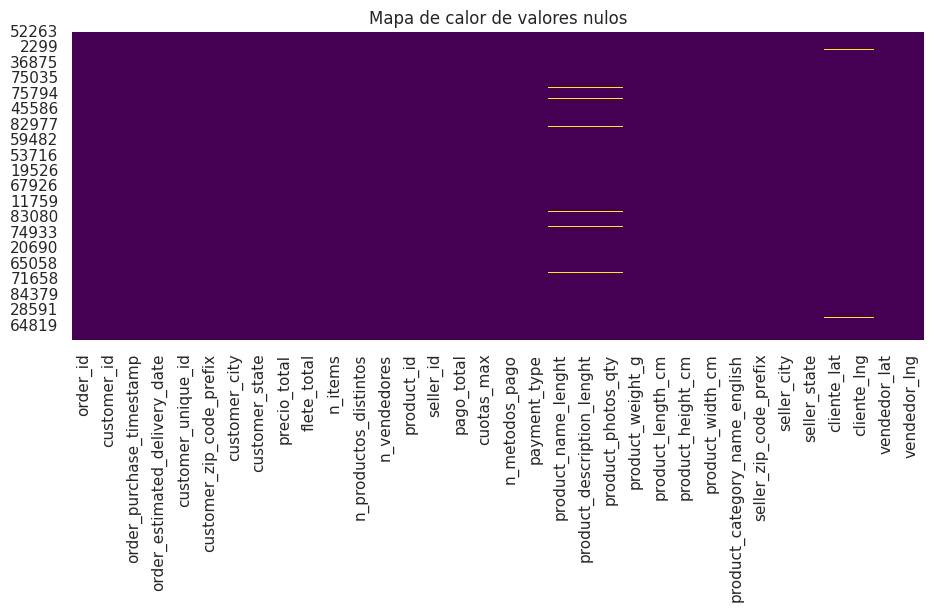

product_photos_qty              2.200
product_description_lenght      2.200
product_name_lenght             2.200
vendedor_lat                    1.000
vendedor_lng                    1.000
product_width_cm                0.800
seller_city                     0.800
precio_total                    0.800
n_productos_distintos           0.800
flete_total                     0.800
product_weight_g                0.800
product_height_cm               0.800
product_length_cm               0.800
seller_id                       0.800
product_id                      0.800
n_vendedores                    0.800
n_items                         0.800
seller_state                    0.800
product_category_name_english   0.800
seller_zip_code_prefix          0.800
dtype: float64
product_weight_g                 vs customer_state  | p = 0.0654 | sin relación -> compatible con MCAR


In [ ]:
# Mapa de calor de nulos (una muestra de 5.000 filas para que sea liviano)
plt.figure(figsize=(11, 4))                                     # tamaño del gráfico
sns.heatmap(df_clean.sample(5000, random_state=42).isnull(), cbar=False, cmap='viridis')  # nulos en amarillo
plt.title('Mapa de calor de valores nulos')                     # título
plt.show()                                                      # muestra el gráfico

print((df_clean.isnull().mean() * 100).round(1).sort_values(ascending=False).head(20))  # % de nulos por columna

# Test de mecanismo de faltantes: ¿la ausencia depende de otra variable observada?
# Filtramos las columnas a evaluar y los grupos para asegurar que existan en df_clean
cols_evaluar = [col for col in ['order_delivered_customer_date', 'product_weight_g'] if col in df_clean.columns]
grupos_evaluar = [grupo for grupo in ['order_status', 'customer_state'] if grupo in df_clean.columns]

for col in cols_evaluar:   # columnas a evaluar (editar según consigna)
    faltante = df_clean[col].isna()                             # máscara de nulos
    for grupo in grupos_evaluar:            # variables candidatas a explicar la ausencia
        tabla = pd.crosstab(df_clean[grupo], faltante)          # tabla de contingencia
        chi2, p, _, _ = stats.chi2_contingency(tabla)           # test chi-cuadrado
        veredicto = 'depende del grupo -> MAR' if p < 0.05 else 'sin relación -> compatible con MCAR'
        print(f'{col:32s} vs {grupo:15s} | p = {p:.4f} | {veredicto}')

In [ ]:
# 1. Eliminación de columnas con más de 50% de nulos
umbral_50 = len(df_clean) * 0.5                                 # mínimo de datos no nulos exigido
cols_antes = set(df_clean.columns)                              # columnas antes
df_clean = df_clean.dropna(axis=1, thresh=umbral_50)            # descarta las que no llegan al umbral
print('Columnas descartadas:', cols_antes - set(df_clean.columns))

# 2. Reglas de la consigna B de Olist
df_clean['review_comment_title'] = df_clean.get('review_comment_title', pd.Series(index=df_clean.index)).fillna('sin_comentario')
df_clean['review_comment_message'] = df_clean.get('review_comment_message', pd.Series(index=df_clean.index)).fillna('sin_comentario')
df_clean['product_category_name_english'] = df_clean['product_category_name_english'].fillna('desconocido')

# 3. Imputación condicional por grupo (ejemplo: peso del producto según su categoría)
df_clean['product_weight_g'] = df_clean.groupby('product_category_name_english')['product_weight_g'] \
    .transform(lambda x: x.fillna(x.median()))                  # mediana dentro de cada categoría

print(df_clean.isnull().sum().sort_values(ascending=False).head(15))  # nulos restantes

Columnas descartadas: set()
product_description_lenght    2191
product_photos_qty            2191
product_name_lenght           2191
vendedor_lat                   993
vendedor_lng                   993
product_length_cm              791
product_height_cm              791
product_width_cm               791
seller_city                    775
seller_state                   775
flete_total                    775
n_items                        775
seller_zip_code_prefix         775
n_productos_distintos          775
n_vendedores                   775
dtype: int64


> **Nota metodológica:** la guía imputa y winsoriza antes del split por claridad didáctica. En un proyecto real, medianas y percentiles se calculan solo con *train* (por ejemplo con `SimpleImputer` dentro del `Pipeline`).

## Paso 4: Detección y tratamiento de outliers
| Método | Criterio | Uso |
|---|---|---|
| IQR | Límite = Q3 + 1.5 × (Q3 − Q1) | Distribuciones asimétricas (precios, fletes, peso) |
| Z-Score | \|Z\| > 3 | Distribuciones con tendencia gaussiana |
| Winsorización | `np.clip(x, p1, p99)` | Acota extremos sin eliminar filas |

precio_total       | IQR [-110.1, 305.9] -> 7913 | Z>3 -> 1709
flete_total        | IQR [-1.4, 39.3] -> 9941 | Z>3 -> 1581
product_weight_g   | IQR [-1950.0, 4050.0] -> 14040 | Z>3 -> 2549
precio_total: máximo antes 13440.0 | después 998.9
flete_total: máximo antes 1795.0 | después 105.0
product_weight_g: máximo antes 40425.0 | después 18250.0


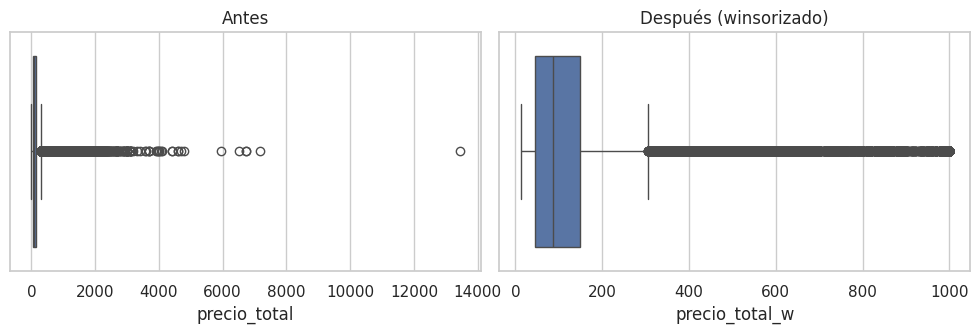

In [ ]:
cols_outliers = ['precio_total', 'flete_total', 'product_weight_g']   # columnas a revisar (editar según consigna)

for c in cols_outliers:                                         # recorre cada columna
    serie = df_clean[c].dropna()                                # descarta nulos para calcular
    Q1, Q3 = serie.quantile(0.25), serie.quantile(0.75)         # cuartiles
    IQR = Q3 - Q1                                               # rango intercuartílico
    lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR           # límites IQR
    out_iqr = ((serie < lim_inf) | (serie > lim_sup)).sum()     # outliers por IQR
    out_z = (np.abs(stats.zscore(serie)) > 3).sum()             # outliers por Z-Score
    print(f'{c:18s} | IQR [{lim_inf:.1f}, {lim_sup:.1f}] -> {out_iqr} | Z>3 -> {out_z}')

# Winsorización al 1% - 99% (crea una columna nueva y conserva la original)
for c in cols_outliers:                                         # recorre cada columna
    p1, p99 = df_clean[c].quantile(0.01), df_clean[c].quantile(0.99)   # percentiles 1 y 99
    df_clean[c + '_w'] = np.clip(df_clean[c], p1, p99)          # acota los extremos
    print(f'{c}: máximo antes {df_clean[c].max():.1f} | después {df_clean[c + "_w"].max():.1f}')

# Gráfico antes / después de la primera columna
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))                 # dos paneles
sns.boxplot(x=df_clean[cols_outliers[0]], ax=ax[0]); ax[0].set_title('Antes')
sns.boxplot(x=df_clean[cols_outliers[0] + '_w'], ax=ax[1]); ax[1].set_title('Después (winsorizado)')
plt.tight_layout(); plt.show()

## Paso 5: Partición y aislamiento de datos (Train-Test Split)
**Regla de oro:** dividir **antes** de escalar, codificar o balancear.
En Olist las órdenes son transacciones en el tiempo, por lo que se recomienda **partición temporal** (entrenar con el pasado, evaluar con el futuro). Si se usa partición aleatoria, `stratify=y` mantiene la proporción de clases.

In [ ]:
from sklearn.model_selection import train_test_split            # función de partición

# Creamos la columna objetivo 'is_delayed' de forma segura desde df_work (que contiene las fechas originales antes de la auditoría de leakage)
df_clean['is_delayed'] = (df_work['order_delivered_customer_date'] > df_work['order_estimated_delivery_date']).astype(int)

# Columnas predictoras: se definen según la consigna (se toman de la configuración E.0)
FEATURES = NUM_STD + NUM_POW + CAT_NOMINAL + CAT_ORDINAL        # lista total de predictoras

if USAR_SPLIT_TEMPORAL:                                         # --- partición cronológica ---
    es_train = df_clean[COL_FECHA_SPLIT] < pd.Timestamp(FECHA_CORTE)   # True = pasado (train)
    X_train, y_train = df_clean.loc[es_train, FEATURES], df_clean.loc[es_train, TARGET]    # set de entrenamiento
    X_test, y_test = df_clean.loc[~es_train, FEATURES], df_clean.loc[~es_train, TARGET]    # set de prueba
else:                                                           # --- partición aleatoria estratificada ---
    X_train, X_test, y_train, y_test = train_test_split(
        df_clean[FEATURES], df_clean[TARGET], test_size=0.2, random_state=42, stratify=df_clean[TARGET])

print(f'Train: {X_train.shape} | Test: {X_test.shape}')         # tamaños
print(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                    'test': y_test.value_counts(normalize=True)}).round(4))  # proporción del target por conjunto

Train: (80450, 12) | Test: (18991, 12)
            train  test
is_delayed             
0           0.915 0.946
1           0.085 0.054


## Paso 6: Transformación de variables e integración en Pipeline
`fit()` **exclusivamente** sobre train. Yeo-Johnson para asimétricas, StandardScaler para simétricas, OneHot para nominales, Ordinal para ordenadas.

In [ ]:
from sklearn.compose import ColumnTransformer                   # aplica transformaciones distintas por columna
from sklearn.pipeline import Pipeline                           # encadena pasos
from sklearn.impute import SimpleImputer                        # imputación aprendida solo con train
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer

transformers = []                                               # lista de transformaciones activas
if NUM_STD:                                                     # numéricas simétricas
    transformers.append(('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                                          ('sc', StandardScaler())]), NUM_STD))
if NUM_POW:                                                     # numéricas asimétricas
    transformers.append(('pow', Pipeline([('imp', SimpleImputer(strategy='median')),
                                          ('pt', PowerTransformer(method='yeo-johnson'))]), NUM_POW))
if CAT_NOMINAL:                                                 # categóricas nominales
    transformers.append(('cat_nom', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), CAT_NOMINAL))
if CAT_ORDINAL:                                                 # categóricas ordinales
    transformers.append(('cat_ord', OrdinalEncoder(categories=ORDEN_ORDINAL, handle_unknown='use_encoded_value',
                                                   unknown_value=-1), CAT_ORDINAL))

preprocessor = ColumnTransformer(transformers=transformers)     # ensambla el preprocesador

# Para evitar conflictos con Pandas 'NAType' en OneHotEncoder, forzamos casteo a tipo string clásico de Python en las categóricas
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

for col in CAT_NOMINAL + CAT_ORDINAL:
    if col in X_train_clean.columns:
        X_train_clean[col] = X_train_clean[col].astype(str)
        X_test_clean[col] = X_test_clean[col].astype(str)

X_train_trans = preprocessor.fit_transform(X_train_clean)       # AJUSTA y transforma solo con train
X_test_trans = preprocessor.transform(X_test_clean)             # solo transforma test (sin ajustar)

print('Columnas resultantes:', list(preprocessor.get_feature_names_out()))
print('Forma Train:', X_train_trans.shape, '| Forma Test:', X_test_trans.shape)

Columnas resultantes: ['num__product_photos_qty', 'num__product_name_lenght', 'num__product_description_lenght', 'pow__precio_total_w', 'pow__flete_total_w', 'pow__product_weight_g_w', 'pow__pago_total', 'pow__cuotas_max', 'pow__n_items', 'cat_nom__payment_type_boleto', 'cat_nom__payment_type_credit_card', 'cat_nom__payment_type_debit_card', 'cat_nom__payment_type_voucher', 'cat_nom__customer_state_al', 'cat_nom__customer_state_am', 'cat_nom__customer_state_ap', 'cat_nom__customer_state_ba', 'cat_nom__customer_state_ce', 'cat_nom__customer_state_df', 'cat_nom__customer_state_es', 'cat_nom__customer_state_go', 'cat_nom__customer_state_ma', 'cat_nom__customer_state_mg', 'cat_nom__customer_state_ms', 'cat_nom__customer_state_mt', 'cat_nom__customer_state_pa', 'cat_nom__customer_state_pb', 'cat_nom__customer_state_pe', 'cat_nom__customer_state_pi', 'cat_nom__customer_state_pr', 'cat_nom__customer_state_rj', 'cat_nom__customer_state_rn', 'cat_nom__customer_state_ro', 'cat_nom__customer_stat

## Paso 7: Balanceo (SMOTE), entrenamiento y evaluación
- SMOTE **solo** sobre train. El test conserva su distribución real.
- Modelo *cost-sensitive* (`class_weight='balanced'`) y *moving threshold* para ganar Recall.
- Métricas: **PR-AUC** (contra la prevalencia como línea base) y **F1** de la clase positiva; la accuracy es engañosa con clases desbalanceadas.

In [ ]:
from imblearn.over_sampling import SMOTE                        # sobremuestreo sintético
from sklearn.ensemble import RandomForestClassifier             # modelo base
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_curve, auc,
                             roc_auc_score, f1_score, precision_score, recall_score)

print('Train antes de SMOTE:', dict(pd.Series(y_train).value_counts()))
smote = SMOTE(random_state=42)                                  # define SMOTE
X_train_res, y_train_res = smote.fit_resample(X_train_trans, y_train)   # balancea SOLO train
print('Train después de SMOTE:', dict(pd.Series(y_train_res).value_counts()))

clf = RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1)  # modelo cost-sensitive
clf.fit(X_train_res, y_train_res)                               # entrena con train balanceado

y_probs = clf.predict_proba(X_test_trans)[:, 1]                 # probabilidad de clase positiva en test
y_pred = (y_probs >= 0.25).astype(int)                          # umbral movido de 0.50 a 0.25

print('\nMatriz de confusión (umbral 0.25):\n', confusion_matrix(y_test, y_pred))
print('\n', classification_report(y_test, y_pred))             # precision, recall y f1 por clase

precision, recall, _ = precision_recall_curve(y_test, y_probs)  # puntos de la curva PR
pr_auc = auc(recall, precision)                                 # área bajo la curva PR
print(f'PR-AUC: {pr_auc:.4f} | ROC-AUC: {roc_auc_score(y_test, y_probs):.4f}')
print(f'Línea base (azar) = prevalencia: {np.mean(y_test):.4f}')

Train antes de SMOTE: {0: np.int64(73642), 1: np.int64(6808)}
Train después de SMOTE: {0: np.int64(73642), 1: np.int64(73642)}

Matriz de confusión (umbral 0.25):
 [[12834  5138]
 [  709   310]]

               precision    recall  f1-score   support

           0       0.95      0.71      0.81     17972
           1       0.06      0.30      0.10      1019

    accuracy                           0.69     18991
   macro avg       0.50      0.51      0.46     18991
weighted avg       0.90      0.69      0.78     18991

PR-AUC: 0.0569 | ROC-AUC: 0.5200
Línea base (azar) = prevalencia: 0.0537


 umbral  precision  recall    f1  positivos_predichos
  0.100      0.056   0.739 0.104                13412
  0.150      0.056   0.564 0.102                10247
  0.200      0.058   0.420 0.101                 7440
  0.250      0.057   0.304 0.096                 5448
  0.300      0.057   0.219 0.091                 3880
  0.400      0.061   0.117 0.080                 1961
  0.500      0.055   0.049 0.052                  914


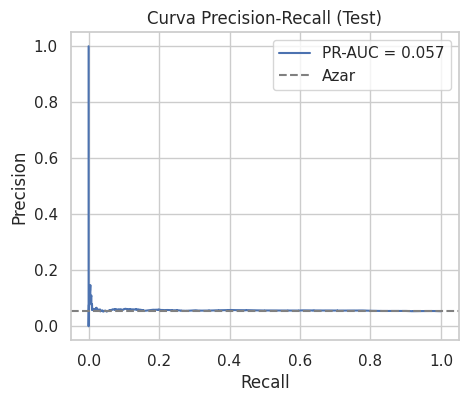

In [ ]:
# Comparación de umbrales sobre test
filas = []                                                      # acumula resultados
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:            # umbrales a probar
    pred = (y_probs >= t).astype(int)                           # predicción con ese umbral
    filas.append({'umbral': t,
                  'precision': precision_score(y_test, pred, zero_division=0),
                  'recall': recall_score(y_test, pred),
                  'f1': f1_score(y_test, pred, zero_division=0),
                  'positivos_predichos': pred.sum()})
print(pd.DataFrame(filas).round(3).to_string(index=False))      # tabla comparativa

plt.figure(figsize=(5, 4))                                      # gráfico de la curva PR
plt.plot(recall, precision, label=f'PR-AUC = {pr_auc:.3f}')     # curva del modelo
plt.axhline(np.mean(y_test), ls='--', c='gray', label='Azar')   # línea base
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Curva Precision-Recall (Test)')
plt.legend(); plt.show()

## Lista de comprobación final (checklist pre-entrenamiento)
| Verificación | Requisito técnico | Riesgo si no se cumple |
|---|---|---|
| ☐ | Partición Train/Test realizada **antes** de transformar y balancear | Data Leakage |
| ☐ | Partición temporal (o estratificada) según corresponda | Distorsión del target / fuga del futuro |
| ☐ | `fit()` solo en Train (ColumnTransformer, SMOTE, modelo) | Contaminación estadística |
| ☐ | `handle_unknown` definido en los encoders | Errores en ejecución |
| ☐ | SMOTE exclusivamente sobre Train | Métricas falsas |
| ☐ | Evaluación con PR-AUC / F1 y no solo Accuracy | Paradoja de la exactitud |
| ☐ | Variables de fuga eliminadas (`COLS_LEAKAGE`) | Rendimiento irreal en producción |

# *Informe de mejoras realizado por alumna Gargiulo Yessica Camila.*

## Aciertos Estructurales y Lógicos

La "Regla de oro" sobre la inmutabilidad de los DataFrames raw_* asegura la trazabilidad y previene la corrupción accidental de los datos base a lo largo del análisis.

La estrategia de uniones (Bloque D) es analíticamente precisa: pre-agregar ítems y pagos a nivel de orden y conservar solo la reseña más reciente evita la duplicación del identificador único order_id durante el ensamblaje del DataFrame maestro.

La división en bloques secuenciales (A-E) crea un flujo reproducible, mientras que la parametrización de variables de fuga y fecha de corte en el Bloque E demuestra un enfoque metodológico maduro para modelos predictivos.

El esquema relacional documenta correctamente las claves primarias (PK) y foráneas (FK), identificando de antemano excepciones estructurales de las tablas


## Hallazgos de Revisión: Errores, Faltas y Riesgos

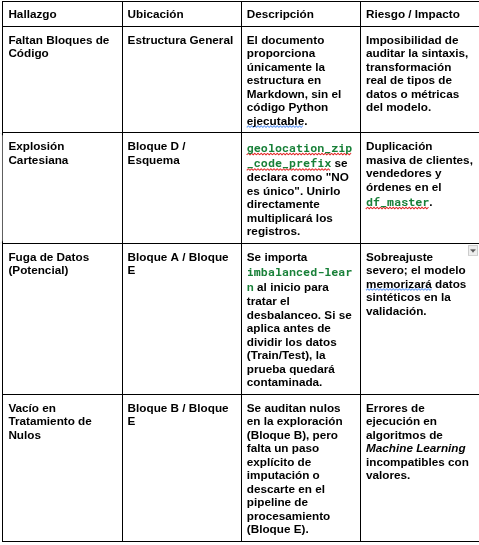


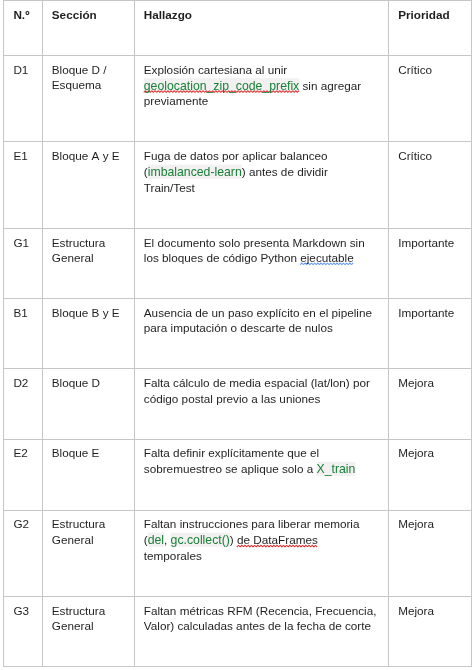

## Posibilidades de Mejora
Agregación Geoespacial Previa: Antes de ejecutar los joins en el Bloque D, agrupa la tabla geolocation por el prefijo del código postal y calcula la media espacial (latitud y longitud). Esto convertirá la clave en única y permitirá una relación 1 a 1 segura con clientes y vendedores.

Control Estricto de SMOTE/Balanceo: Define explícitamente en el Bloque E que cualquier técnica de sobremuestreo (proveniente de imbalanced-learn) se ejecutará estrictamente sobre el conjunto de entrenamiento (X_train, y_train), dejando el conjunto de prueba inalterado.

Optimización de Memoria: Al trabajar con aproximadamente 100.000 órdenes y 9 tablas, incorpora instrucciones explícitas para usar del o gc.collect() sobre los DataFrames de trabajo temporales (items, payments) una vez que el df_master esté completamente consolidado.

Ingeniería de Características RFM: Al tratarse de un modelo transaccional de e-commerce, incorpora explícitamente en el pipeline métricas calculadas de Recencia, Frecuencia y Valor Monetario a nivel de cliente antes de aplicar la fecha de corte.


## Conclusión
La plantilla presenta una arquitectura conceptual sólida y defensiva, destacando por su rigor en el aislamiento de los datos crudos y su meticulosa planificación para evitar la duplicación de órdenes al integrar tablas transaccionales de 1 a N. El principal punto de fallo estructural reside en la integración de la tabla geoespacial, cuya falta de exclusividad romperá la integridad del DataFrame maestro si no se aborda mediante una etapa previa de agregación. Resolviendo esta anomalía espacial y garantizando la ubicación metodológica correcta para el balanceo de clases y la imputación de nulos, el esqueleto se convertirá en un flujo de trabajo analítico de grado de producción.